# Model benchmark: `src/starter_kit/models.py` × {per-class, multiclass} × split ratios × CV folds
- **Outer split** (by compound, stratified by class): 80/20, 75/25, 85/15 → held-out validation set.
- **Inner CV** on the training part: grouped, stratified k-fold, k = 4…10.
- **Validation**: fit on the training part, macro-F1 with a 1,000× bootstrap over validation compounds (95% CI).
- **Modes**: `per_class` = one binary model per class (one-vs-rest); `multiclass` = one model for all classes.
- **Biology**: every validation/test call is checked against the expected pathway readout of the called class (PROGENy, MSigDB Hallmark, HSF1 heat shock); robust z ≥ 1 = supported.
- **Ensembles** on top of the per-class models: soft vote (`ens_mean`) and a stacked logistic regression (`ens_stack`).
- **Diagnostics**: confusion matrices (official `cv_fold` CV), DEGs per class × dose, within-class variability, clustering / batch correction, signature similarity, and a per-class "why is this class not learned" table.
- Outputs go to `results/benchmark/`.

In [1]:
import os, sys, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from joblib import Parallel, delayed
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, confusion_matrix, silhouette_score
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
warnings.filterwarnings("ignore"); os.environ["PYTHONWARNINGS"] = "ignore"

ROOT = Path(os.getenv("ROOT", ".."))   # notebook lives in src/
OUT = Path(os.getenv("OUT_DIR", ROOT / "results" / "benchmark")); (OUT / "submissions").mkdir(parents=True, exist_ok=True)
KIT = ROOT / "src" / "starter_kit"; sys.path.insert(0, str(KIT)); os.environ["PYTHONPATH"] = str(KIT)  # workers need it too
from models import MODELS, make_model          # centroid, knn, logreg, rf, mlp
from evaluate import compound_metrics
from train import activity, aggregate

SEED, RATIOS, KS, MODES, N_BOOT, MAX_REPS, MIN_ACTIVE = 2026, [0.20, 0.25, 0.15], range(4, 11), ["per_class", "multiclass"], 1000, 6, 20
lab = lambda f: f"{round(100 * (1 - f))}/{round(100 * f)}"

## Data
The one compound with 300 replicate signatures (all at 20 µM) is capped at `MAX_REPS` signatures so it cannot dominate training.

In [2]:
X = pd.read_csv(ROOT / "X_train.csv.gz", index_col=0)
y = pd.read_csv(ROOT / "y_train.csv", index_col=0)["moa"].loc[X.index]
meta = pd.read_csv(ROOT / "meta_train.csv", index_col=0).loc[X.index]
Xte = pd.read_csv(ROOT / "X_test.csv.gz", index_col=0); mte = pd.read_csv(ROOT / "meta_test.csv", index_col=0).loc[Xte.index]

ms = meta.sample(frac=1, random_state=SEED); keep = ms.index[ms.groupby("compound").cumcount() < MAX_REPS]
X, y, meta = X.loc[keep], y.loc[keep], meta.loc[keep]
cpd = y.groupby(meta.compound).first(); classes = sorted(cpd.unique())
allm = pd.concat([meta, mte]); assert allm.index.is_unique
print(X.shape, "train signatures |", len(cpd), "train compounds |", mte.compound.nunique(), "test compounds")

(521, 978) train signatures | 87 train compounds | 29 test compounds


## Pathway readouts (biology check)
Compound profile = mean pathway z-score over doses ≥ 3.33 µM, scored against a gene-permutation null and robust-standardized over training compounds. `+` up, `-` down, `~` changed in either direction.

**Sources** (details, versions and rebuild script: `pathway_resources/README.md`): PROGENy footprints — Schubert et al. 2018, [doi:10.1038/s41467-017-02391-6](https://doi.org/10.1038/s41467-017-02391-6), Bioconductor `progeny` 1.32.0; MSigDB Hallmark — Liberzon et al. 2015, [doi:10.1016/j.cels.2015.12.004](https://doi.org/10.1016/j.cels.2015.12.004), release 2026.1 via `msigdbr` 26.1.1 ([Zenodo 18968178](https://zenodo.org/records/18968178)); probe→symbol `hgu133a.db` 3.13.0; HSF1 heat-shock set hand-picked. The class → readout mapping (`PRIORS`) is our own, from target biology.

In [3]:
W = pd.read_csv(ROOT / "pathway_resources" / "l1000_pathway_weights.csv", index_col=0).drop(columns="symbol")

def pathway_z(Xs, n_perm=500, rng=np.random.default_rng(SEED)):
    Xv, Wv = Xs[W.index].values, W.values
    null = np.stack([Xv @ Wv[rng.permutation(len(Wv))] for _ in range(n_perm)])
    return pd.DataFrame((Xv @ Wv - null.mean(0)) / null.std(0), index=Xs.index, columns=W.columns)

hi = allm.dose_um >= 3.33
P = pathway_z(pd.concat([X, Xte])[hi]).groupby(allm.compound[hi]).mean()
med = P.loc[cpd.index].median(); P = (P - med) / (1.4826 * (P.loc[cpd.index] - med).abs().median())

PRIORS = {"EGFR": "PROGENy:EGFR- PROGENy:MAPK-", "MEK": "PROGENy:MAPK- PROGENy:EGFR-", "RAF": "PROGENy:MAPK-",
          "PI3K": "PROGENy:PI3K- H:MTORC1_SIGNALING-", "AKT": "PROGENy:PI3K- H:MTORC1_SIGNALING-", "mTOR": "H:MTORC1_SIGNALING- PROGENy:PI3K-",
          "JAK": "PROGENy:JAK-STAT- H:IL6_JAK_STAT3_SIGNALING-", "CDK": "H:E2F_TARGETS- H:G2M_CHECKPOINT-",
          "PLK": "H:G2M_CHECKPOINT~ H:MITOTIC_SPINDLE~", "tubulin": "H:G2M_CHECKPOINT~ H:MITOTIC_SPINDLE~",
          "topoisomerase": "PROGENy:p53+ H:E2F_TARGETS-", "PARP": "PROGENy:p53+ H:DNA_REPAIR~",
          "HSP": "custom:HSF1_heat_shock+", "proteasome": "H:UNFOLDED_PROTEIN_RESPONSE+ custom:HSF1_heat_shock+", "HDAC": ""}
PRIORS = {next(c for c in classes if c.startswith(k + " ")): [(t[:-1], {"+": 1, "-": -1, "~": 0}[t[-1]]) for t in v.split()] for k, v in PRIORS.items()}

def support(compounds, calls):
    """Mean signed readout of the called class per compound (NaN = class has no readout, e.g. HDAC)."""
    return pd.Series([np.mean([s * P.loc[c, f] if s else abs(P.loc[c, f]) for f, s in PRIORS[k]]) if PRIORS[k] else np.nan
                      for c, k in zip(compounds, calls)], index=list(compounds))

## Models, modes, splits

In [4]:
def fit_predict(name, Xf, yf, Xp):
    keep = activity(Xf) >= MIN_ACTIVE                       # kit's activity filter (training rows only)
    if yf[keep].nunique() < yf.nunique(): keep[:] = True
    m = make_model(name)
    if name == "rf": m.est.set_params(n_jobs=1)             # parallelism is across jobs instead
    try: m.fit(Xf[keep], yf[keep])
    except ValueError:                                     # MLP early stopping on tiny classes (as in train.py)
        if name != "mlp": raise
        m.est.set_params(mlpclassifier__early_stopping=False); m.fit(Xf[keep], yf[keep])
    return m.predict_proba(Xp)

def scores(name, mode, Xf, yf, Xp):
    """Compound × class scores; doses combined with the kit's activity-weighted mean."""
    if mode == "multiclass": S = fit_predict(name, Xf, yf, Xp)
    else: S = pd.DataFrame({c: fit_predict(name, Xf, yf.where(yf == c, "rest"), Xp)[c] for c in sorted(yf.unique())})
    return aggregate(S.reindex(columns=classes, fill_value=0.0), allm.compound, activity(Xp))

def holdout(frac):
    """Per class, `frac` of its compounds (≥1) go to validation."""
    rng = np.random.default_rng(SEED)
    return [c for _, g in cpd.groupby(cpd) for c in rng.permutation(g.index)[:max(1, round(frac * len(g)))]]

def run(frac, name, mode, k):
    tr = ~meta.compound.isin(holdout(frac)); Xt, yt = X[tr], y[tr]
    if k:   # inner CV on the training part
        cv = StratifiedGroupKFold(k, shuffle=True, random_state=SEED).split(Xt, yt, meta.compound[tr])
        S = pd.concat([scores(name, mode, Xt.iloc[a], yt.iloc[a], Xt.iloc[b]) for a, b in cv])
        return "cv", (dict(ratio=lab(frac), model=name, mode=mode, k=k, **compound_metrics(S, cpd.loc[S.index])), S)  # keep OOF scores for stacking
    return "val", (lab(frac), name, mode, scores(name, mode, Xt, yt, X[~tr]))

print({lab(f): len(holdout(f)) for f in RATIOS}, "validation compounds")

{'80/20': 19, '75/25': 22, '85/15': 17} validation compounds


## Run everything (parallel)

In [5]:
jobs = [(f, n, m, k) for n in ["rf", "mlp", "logreg", "knn", "centroid"] for m in MODES for f in RATIOS for k in [*KS, 0]]
out = Parallel(n_jobs=-1, verbose=10)(delayed(run)(*j) for j in jobs)
test = dict(zip([(n, m) for n in MODELS for m in MODES],
                Parallel(n_jobs=-1)(delayed(scores)(n, m, X, y, Xte) for n in MODELS for m in MODES)))
cv = pd.DataFrame([v[0] for t, v in out if t == "cv"])
oof = {(v[0]["ratio"], v[0]["model"], v[0]["mode"], v[0]["k"]): v[1] for t, v in out if t == "cv"}   # out-of-fold compound scores
valS = {v[:3]: v[3] for t, v in out if t == "val"}
cv.pivot_table(index=["model", "mode"], columns="k", values="macro_f1").round(2)  # mean over the 3 ratios

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 20 concurrent workers.


[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:   16.2s


[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:  1.0min


[Parallel(n_jobs=-1)]: Done  21 tasks      | elapsed:  1.4min


[Parallel(n_jobs=-1)]: Done  32 tasks      | elapsed:  1.6min


[Parallel(n_jobs=-1)]: Done  45 tasks      | elapsed:  1.9min


... (7 outputs left out)

[Parallel(n_jobs=-1)]: Done 181 tasks      | elapsed:  3.1min


[Parallel(n_jobs=-1)]: Done 226 out of 240 | elapsed:  3.2min remaining:   11.8s


[Parallel(n_jobs=-1)]: Done 240 out of 240 | elapsed:  3.2min finished


k                      4     5     6     7     8     9     10
model    mode                                                
centroid multiclass  0.63  0.61  0.64  0.63  0.61  0.62  0.62
         per_class   0.57  0.58  0.57  0.57  0.55  0.56  0.55
knn      multiclass  0.56  0.58  0.57  0.57  0.58  0.56  0.56
         per_class   0.56  0.58  0.57  0.57  0.58  0.56  0.56
logreg   multiclass  0.61  0.63  0.62  0.61  0.61  0.61  0.60
         per_class   0.62  0.61  0.63  0.62  0.62  0.59  0.60
mlp      multiclass  0.58  0.60  0.62  0.62  0.60  0.62  0.58
         per_class   0.59  0.58  0.56  0.59  0.58  0.58  0.60
rf       multiclass  0.60  0.59  0.57  0.60  0.58  0.56  0.57
         per_class   0.58  0.55  0.56  0.53  0.56  0.54  0.54

## Ensemble on top of the per-class models
- `ens_mean`: soft vote, the mean of the 5 per-class models' compound × class scores.
- `ens_stack`: stacking. One logistic regression on (compound, class) pairs whose 5 features are the 5 models' scores for that class (target: is this the true class). It is trained on **out-of-fold** scores only: inner CV (k = `K_STACK`) of the training part for the validation splits, and the official `cv_fold` CV of all training data for the test submission.

The same out-of-fold run on the official folds (`full`, every model × mode) also drives the confusion matrices below.

In [6]:
ENS, K_STACK = ["ens_mean", "ens_stack"], 5
ALL = [*MODELS, *ENS]

def ens_mean(Ss):
    return sum(S.loc[Ss[0].index, classes] for S in Ss) / len(Ss)

def _long(Ss):
    idx = Ss[0].index
    return np.stack([S.loc[idx, classes].values.ravel() for S in Ss], 1), idx

def fit_stack(Ss, truth):
    F, idx = _long(Ss); t = (truth.loc[idx].to_numpy(object)[:, None] == np.array(classes)[None]).ravel()
    return LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000).fit(F, t)

def apply_stack(st, Ss):
    F, idx = _long(Ss); p = st.predict_proba(F)[:, 1].reshape(len(idx), len(classes))
    return pd.DataFrame(p / p.sum(1, keepdims=True), index=idx, columns=classes)

def metrics_of(S): return compound_metrics(S, cpd.loc[S.index])

# inner CV: soft vote of the base models' out-of-fold scores (the stacker is trained on those, so it has no inner-CV score)
cv = pd.concat([cv, pd.DataFrame([dict(ratio=lab(f), model="ens_mean", mode="per_class", k=k,
                                       **metrics_of(ens_mean([oof[lab(f), n, "per_class", k] for n in MODELS]))) for f in RATIOS for k in KS])],
               ignore_index=True)
cv.to_csv(OUT / "inner_cv.csv", index=False)

# validation splits
ens_val, stackers = [], {}
for f in RATIOS:
    r = lab(f); Sv = [valS[r, n, "per_class"] for n in MODELS]
    stackers[r] = fit_stack([oof[r, n, "per_class", K_STACK] for n in MODELS], cpd)
    ens_val += [(r, "ens_mean", "per_class", ens_mean(Sv)), (r, "ens_stack", "per_class", apply_stack(stackers[r], Sv))]

# out-of-fold scores on ALL training compounds with the official cv_fold split (every model x mode)
folds = [(np.flatnonzero(meta.cv_fold != f), np.flatnonzero(meta.cv_fold == f)) for f in sorted(meta.cv_fold.unique())]
jobs2 = [(n, m) for n in ["rf", "mlp", "logreg", "knn", "centroid"] for m in MODES]
parts = Parallel(n_jobs=-1)(delayed(scores)(n, m, X.iloc[a], y.iloc[a], X.iloc[b]) for n, m in jobs2 for a, b in folds)
full = {j: pd.concat(parts[i * len(folds):(i + 1) * len(folds)]) for i, j in enumerate(jobs2)}
full = {(n, m): full[n, m] for n in MODELS for m in MODES}
Fp = [full[n, "per_class"] for n in MODELS]
full["ens_mean", "per_class"] = ens_mean(Fp)
fold_of = meta.groupby("compound").cv_fold.first()
full["ens_stack", "per_class"] = pd.concat([apply_stack(fit_stack([S[fold_of.loc[S.index] != f] for S in Fp], cpd),
                                                        [S[fold_of.loc[S.index] == f] for S in Fp]) for f in sorted(fold_of.unique())])
fullcv = pd.DataFrame([dict(model=n, mode=m, **metrics_of(S)) for (n, m), S in full.items()])
fullcv.to_csv(OUT / "cv_official_folds.csv", index=False)

# test: base models fitted on all training data, stacker fitted on the official-fold OOF scores
St = [test[n, "per_class"] for n in MODELS]
test["ens_mean", "per_class"] = ens_mean(St)
test["ens_stack", "per_class"] = apply_stack(st_full := fit_stack(Fp, cpd), St)
print("stacker weights (test model):", dict(zip(MODELS, st_full.coef_[0].round(2))), "intercept", st_full.intercept_.round(2))
fullcv.sort_values("macro_f1", ascending=False)

stacker weights (test model): {'centroid': np.float64(4.11), 'knn': np.float64(2.88), 'logreg': np.float64(2.12), 'rf': np.float64(2.49), 'mlp': np.float64(0.55)} intercept [-3.05]


,model,mode,n_compounds,macro_f1,balanced_accuracy,top1,top3
11,ens_stack,per_class,87,0.6942,0.7000,0.7356,0.8276
9,mlp,multiclass,87,0.6663,0.6660,0.7126,0.8046
7,rf,multiclass,87,0.6649,0.6872,0.7356,0.8161
1,centroid,multiclass,87,0.6563,0.6611,0.7011,0.8276
10,ens_mean,per_class,87,0.6444,0.6666,0.7126,0.8161
2,knn,per_class,87,0.6382,0.6750,0.6897,0.7816
3,knn,multiclass,87,0.6382,0.6750,0.6897,0.7816
4,logreg,per_class,87,0.6293,0.6438,0.6897,0.8046
8,mlp,per_class,87,0.6262,0.6433,0.6897,0.7586
5,logreg,multiclass,87,0.6137,0.6211,0.6667,0.8276


## Validation: bootstrap + pathway check

In [7]:
rng = np.random.default_rng(SEED); rows, vp, pc = [], [], []
for r, n, m, S in [v for t, v in out if t == "val"] + ens_val:
    t, p = cpd.loc[S.index], S.idxmax(1); sup = support(S.index, p); ok, s = t == p, sup >= 1
    f1 = lambda i: f1_score(t.values[i], p.values[i], average="macro", labels=np.unique(t.values[i]), zero_division=0)
    b = [f1(i) for i in rng.integers(0, len(t), (N_BOOT, len(t)))]
    rows.append(dict(ratio=r, model=n, mode=m, n_val=len(t), macro_f1=f1(slice(None)), boot_median=np.median(b),
                     ci_lo=np.percentile(b, 2.5), ci_hi=np.percentile(b, 97.5), frac_supported=s.mean(),
                     acc_supported=ok[s].mean(), acc_unsupported=ok[~s & sup.notna()].mean()))
    vp.append(pd.DataFrame(dict(ratio=r, model=n, mode=m, true=t, pred=p, readout=sup)).rename_axis("compound"))
    pc.append(pd.Series(f1_score(t, p, labels=classes, average=None, zero_division=0), index=classes, name=(r, n, m)))
val = pd.DataFrame(rows).round(3); val.to_csv(OUT / "validation_bootstrap.csv", index=False)
pd.concat(vp).to_csv(OUT / "validation_predictions.csv")
pd.DataFrame(pc).round(2).rename_axis(["ratio", "model", "mode"]).to_csv(OUT / "validation_per_class_f1.csv")
val.sort_values("macro_f1", ascending=False).head(10)

,ratio,model,mode,n_val,macro_f1,boot_median,ci_lo,ci_hi,frac_supported,acc_supported,acc_unsupported
4,75/25,rf,multiclass,22,0.670,0.657,0.476,0.843,0.455,1.000,0.364
25,75/25,centroid,per_class,22,0.615,0.635,0.448,0.816,0.455,0.900,0.455
3,80/20,rf,multiclass,19,0.606,0.607,0.403,0.804,0.421,1.000,0.300
34,85/15,ens_mean,per_class,17,0.604,0.611,0.407,0.836,0.529,0.778,0.500
32,75/25,ens_mean,per_class,22,0.598,0.622,0.436,0.833,0.455,0.900,0.455
24,80/20,centroid,per_class,19,0.597,0.594,0.389,0.800,0.421,0.875,0.400
28,75/25,centroid,multiclass,22,0.596,0.625,0.440,0.818,0.455,0.900,0.455
33,75/25,ens_stack,per_class,22,0.591,0.610,0.433,0.817,0.455,0.900,0.455
16,75/25,logreg,multiclass,22,0.584,0.610,0.426,0.804,0.500,0.818,0.500
13,75/25,logreg,per_class,22,0.584,0.606,0.425,0.804,0.500,0.818,0.500


### Per-class models vs ensembles
Validation (mean over the 3 splits, with the mean bootstrap CI), inner CV (mean over splits and k), and the official 4-fold `cv_fold` CV on all 87 training compounds.

In [8]:
cmp = (val.groupby(["model", "mode"])[["macro_f1", "ci_lo", "ci_hi", "frac_supported"]].mean().add_prefix("val_")
       .join(cv.groupby(["model", "mode"]).macro_f1.mean().rename("inner_cv_f1"))
       .join(fullcv.set_index(["model", "mode"])[["macro_f1", "balanced_accuracy", "top3"]].add_prefix("official_cv_"))).round(3)
cmp.to_csv(OUT / "model_comparison.csv")
cmp.xs("per_class", level="mode").sort_values("val_macro_f1", ascending=False)

,val_macro_f1,val_ci_lo,val_ci_hi,val_frac_supported,inner_cv_f1,official_cv_macro_f1,official_cv_balanced_accuracy,official_cv_top3
model,,,,,,,,
ens_mean,0.593,0.417,0.827,0.468,0.615,0.644,0.667,0.816
centroid,0.588,0.396,0.791,0.449,0.566,0.598,0.611,0.839
ens_stack,0.555,0.379,0.791,0.449,NaN,0.694,0.700,0.828
logreg,0.535,0.372,0.765,0.501,0.613,0.629,0.644,0.805
knn,0.533,0.368,0.789,0.449,0.569,0.638,0.675,0.782
mlp,0.505,0.329,0.728,0.471,0.583,0.626,0.643,0.759
rf,0.473,0.303,0.680,0.518,0.551,0.589,0.604,0.828


## Test predictions: one submission per model × mode, with pathway support

In [9]:
for (n, m), S in test.items(): S.rename_axis("compound").reset_index().to_csv(OUT / "submissions" / f"submission_{n}_{m}.csv", index=False)
calls = pd.DataFrame({f"{n}|{m}": S.idxmax(1) for (n, m), S in test.items()})
tsup = pd.DataFrame({c: support(calls.index, calls[c]) for c in calls})
calls.join(tsup.round(2), rsuffix=" readout").to_csv(OUT / "test_calls_with_pathway_readout.csv")
tsum = pd.DataFrame({"frac_supported": (tsup >= 1).mean(), "n_no_readout": tsup.isna().sum(),
                     "agree_with_consensus": calls.eq(calls.mode(axis=1)[0], axis=0).mean()}).round(2)
tsum.to_csv(OUT / "test_pathway_summary.csv"); tsum.sort_values("frac_supported", ascending=False)

,frac_supported,n_no_readout,agree_with_consensus
centroid|per_class,0.52,3,0.93
centroid|multiclass,0.52,3,1.00
mlp|multiclass,0.52,4,0.86
logreg|multiclass,0.52,3,0.93
rf|multiclass,0.48,3,0.76
ens_mean|per_class,0.48,3,0.97
rf|per_class,0.48,3,0.76
logreg|per_class,0.48,3,0.90
ens_stack|per_class,0.48,3,0.97
knn|per_class,0.45,3,0.79


## Figures

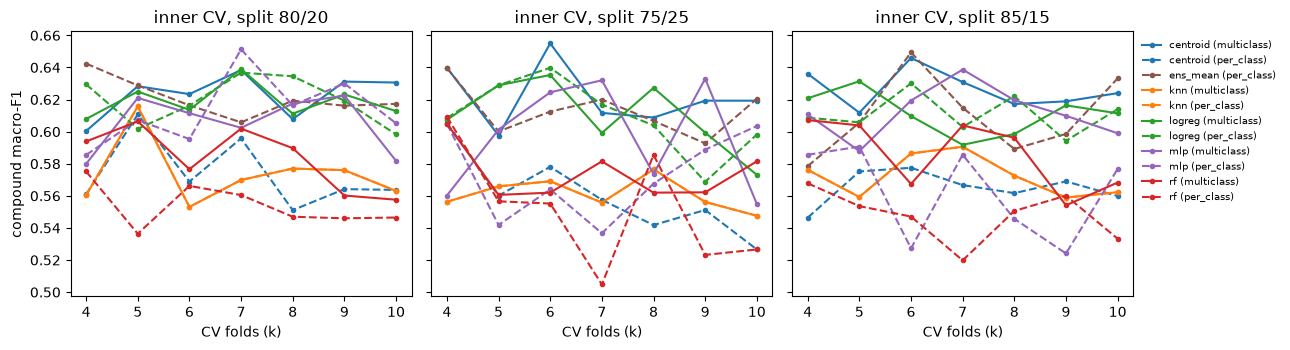

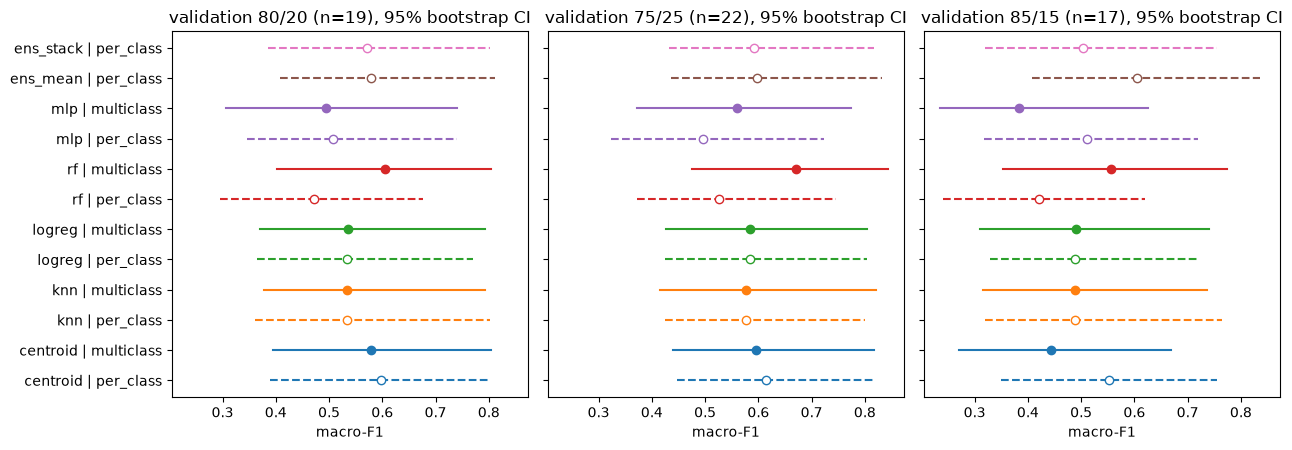

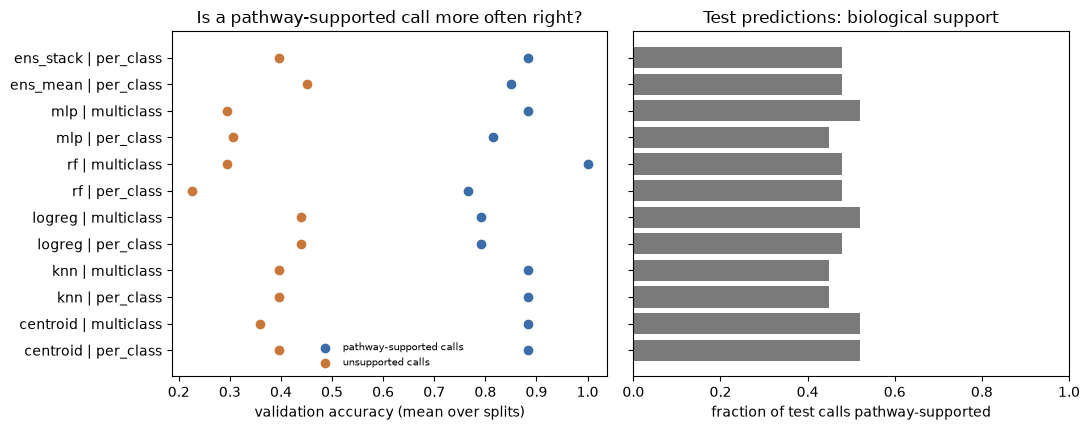

In [10]:
cols = dict(zip(ALL, plt.cm.tab10.colors)); ls = {"multiclass": "-", "per_class": "--"}
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, r in zip(axs, map(lab, RATIOS)):
    for (n, m), g in cv[cv.ratio == r].groupby(["model", "mode"]): ax.plot(g.k, g.macro_f1, ls[m], color=cols[n], marker="o", ms=3, label=f"{n} ({m})")
    ax.set(title=f"inner CV, split {r}", xlabel="CV folds (k)")
axs[0].set_ylabel("compound macro-F1"); axs[-1].legend(fontsize=7, frameon=False, bbox_to_anchor=(1, 1)); fig.tight_layout(); fig.savefig(OUT / "fig_inner_cv_vs_k.png", dpi=150)

fig, axs = plt.subplots(1, 3, figsize=(13, 4.6), sharex=True, sharey=True)
order = [(n, m) for n in MODELS for m in MODES] + [(e, "per_class") for e in ENS]
for ax, r in zip(axs, map(lab, RATIOS)):
    v = val[val.ratio == r].set_index(["model", "mode"]).loc[order]
    for i, ((n, m), row) in enumerate(v.iterrows()):
        ax.plot([row.ci_lo, row.ci_hi], [i, i], color=cols[n], ls=ls[m]); ax.plot(row.macro_f1, i, "o", color=cols[n], mfc="white" if m == "per_class" else cols[n])
    ax.set(title=f"validation {r} (n={int(v.n_val.iloc[0])}), 95% bootstrap CI", xlabel="macro-F1", yticks=range(len(order)), yticklabels=[f"{n} | {m}" for n, m in order])
fig.tight_layout(); fig.savefig(OUT / "fig_validation_bootstrap.png", dpi=150)

g = val.groupby(["model", "mode"])[["acc_supported", "acc_unsupported", "frac_supported"]].mean().loc[order].join(tsum.set_axis(pd.MultiIndex.from_tuples([tuple(i.split("|")) for i in tsum.index], names=["model", "mode"])), rsuffix="_test")
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True); yy = np.arange(len(order))
axs[0].scatter(g.acc_supported, yy, color="#3b6ea8", label="pathway-supported calls"); axs[0].scatter(g.acc_unsupported, yy, color="#c9773a", label="unsupported calls")
axs[0].set(xlabel="validation accuracy (mean over splits)", yticks=yy, yticklabels=[f"{n} | {m}" for n, m in order], title="Is a pathway-supported call more often right?"); axs[0].legend(fontsize=7, frameon=False)
axs[1].barh(yy, g.frac_supported_test, color="#7a7a7a"); axs[1].set(xlabel="fraction of test calls pathway-supported", title="Test predictions: biological support", xlim=(0, 1))
fig.tight_layout(); fig.savefig(OUT / "fig_pathway_check.png", dpi=150)

## Confusion matrices: which targets are not learned?
Official `cv_fold` CV on all training compounds: every compound is predicted exactly once by a model that never saw it. Row-normalized colour; numbers = compounds.

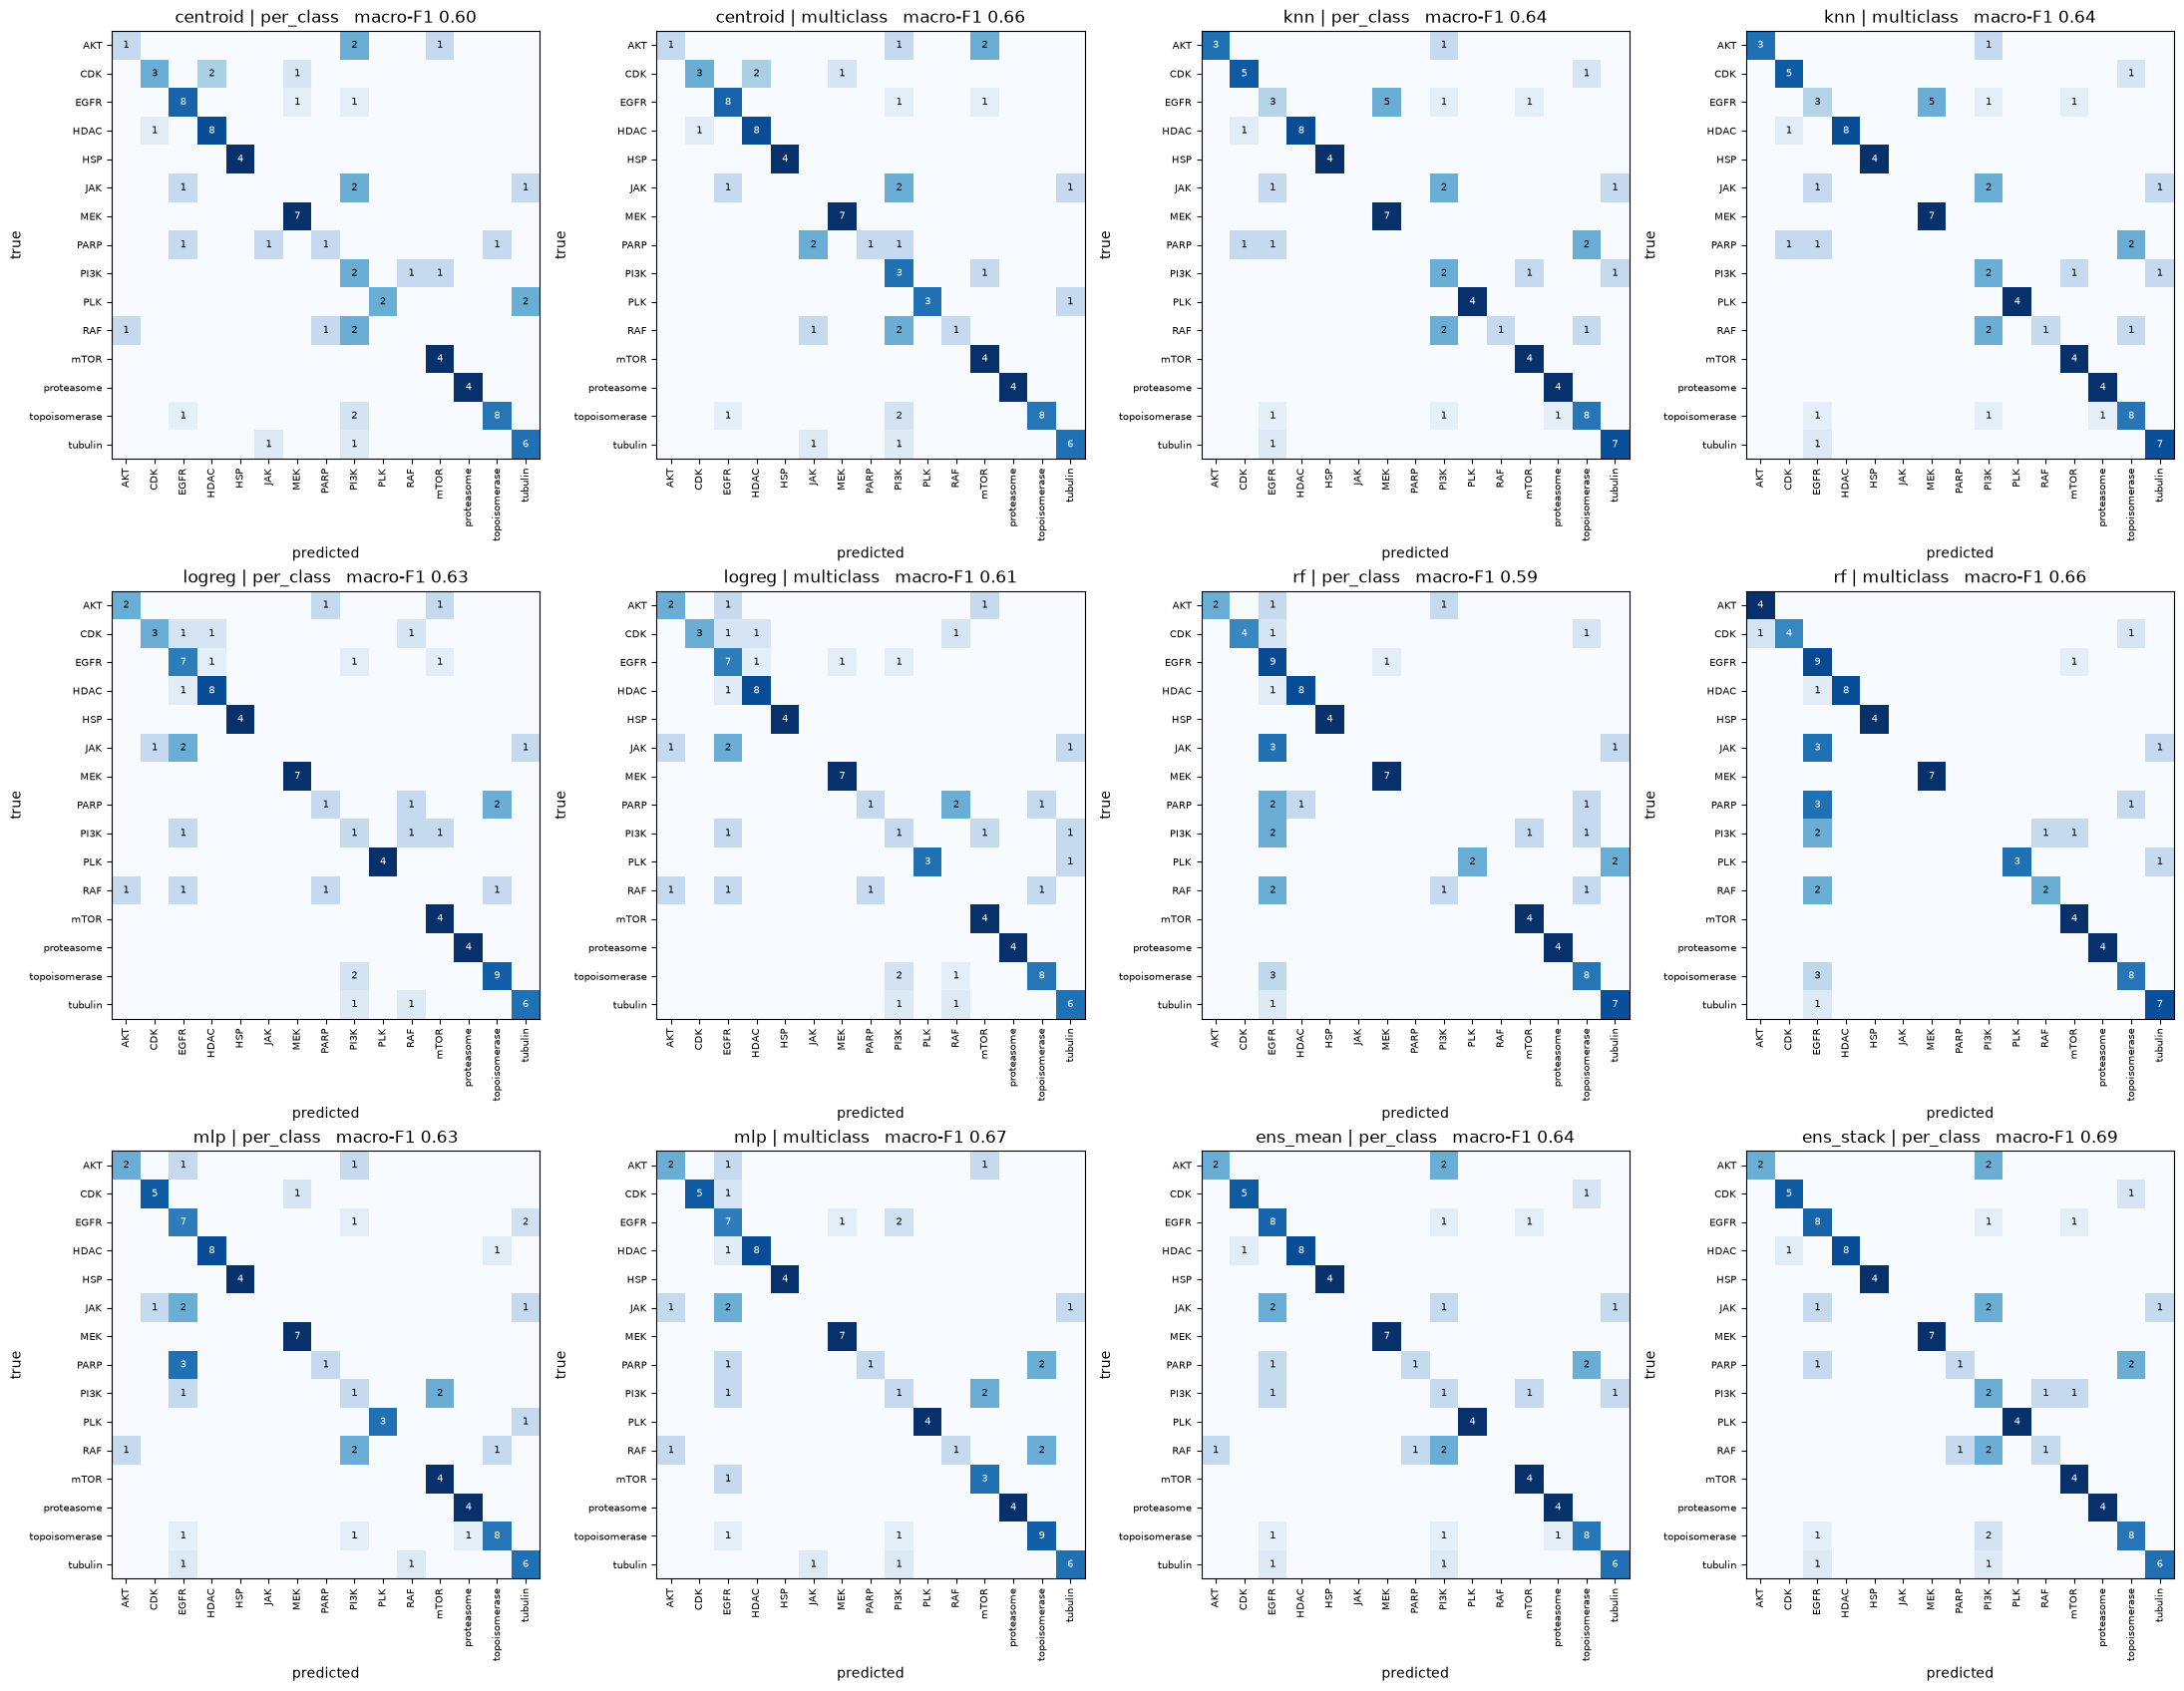

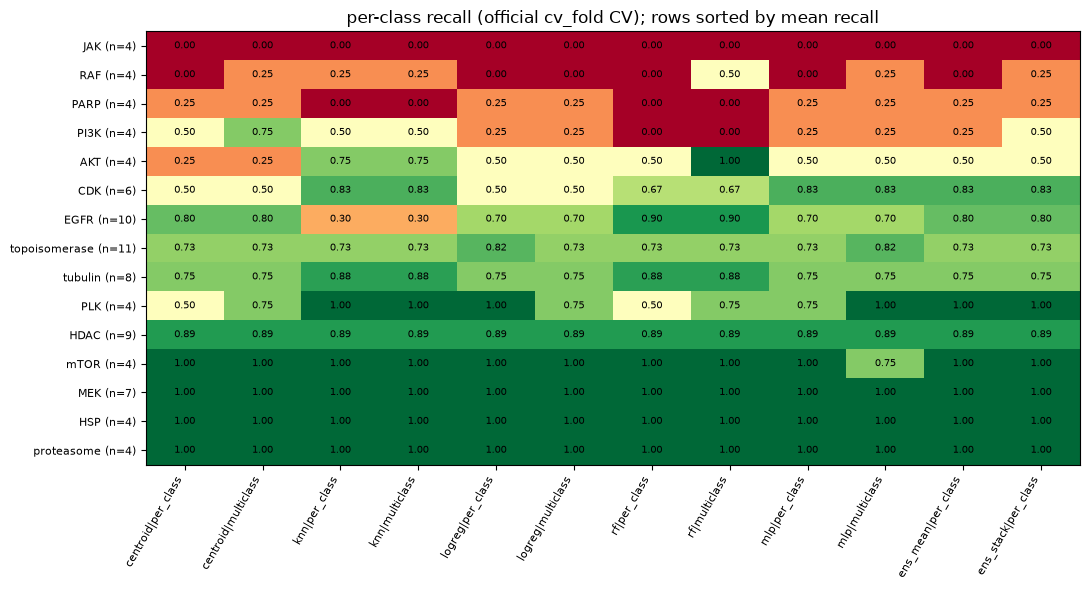

In [11]:
short = lambda c: c.replace(" polymerization", "").replace(" inhibitor", "")
CM = {j: pd.DataFrame(confusion_matrix(cpd.loc[S.index], S.idxmax(1), labels=classes), index=classes, columns=classes) for j, S in full.items()}
pd.concat({f"{n}|{m}": c for (n, m), c in CM.items()}, names=["model", "true"]).to_csv(OUT / "confusion_official_folds.csv")
f1o = fullcv.set_index(["model", "mode"]).macro_f1

fig, axs = plt.subplots(3, 4, figsize=(22, 17))
for ax, j in zip(axs.flat, order):
    c = CM[j]; r = c.div(c.sum(1), axis=0)
    ax.imshow(r.values, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(classes)):
        for k in range(len(classes)):
            if c.iat[i, k]: ax.text(k, i, c.iat[i, k], ha="center", va="center", fontsize=7, color="white" if r.iat[i, k] > .5 else "black")
    ax.set(title=f"{j[0]} | {j[1]}   macro-F1 {f1o[j]:.2f}", xticks=range(15), yticks=range(15), xlabel="predicted", ylabel="true")
    ax.set_xticklabels(map(short, classes), rotation=90, fontsize=7); ax.set_yticklabels(map(short, classes), fontsize=7)
fig.tight_layout(); fig.savefig(OUT / "fig_confusion_matrices.png", dpi=130)

rec = pd.DataFrame({f"{n}|{m}": np.diag(CM[n, m]) / CM[n, m].sum(1).values for n, m in order}, index=classes)
rec = rec.loc[rec.mean(1).sort_values().index]; rec.round(3).to_csv(OUT / "recall_per_class_official_folds.csv")
fig, ax = plt.subplots(figsize=(11, 6))
ax.imshow(rec.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
for i in range(rec.shape[0]):
    for k in range(rec.shape[1]): ax.text(k, i, f"{rec.iat[i, k]:.2f}", ha="center", va="center", fontsize=7)
ax.set(xticks=range(rec.shape[1]), yticks=range(len(rec)), title="per-class recall (official cv_fold CV); rows sorted by mean recall")
ax.set_xticklabels(rec.columns, rotation=60, ha="right", fontsize=8); ax.set_yticklabels([f"{short(c)} (n={cpd.eq(c).sum()})" for c in rec.index], fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "fig_recall_per_class.png", dpi=150)

## Plot 1: DEGs per class and dose
DEG = gene with |z| > 2 in a signature. Left: median number of DEGs per signature for each class × dose (20 µM exists for one compound only). Right: dose response; dashed black = test compounds, grey dotted = the kit's activity filter, red dotted = noise floor (median DEGs of all 0.04 µM signatures, which are close to untreated). Second figure: the 12 strongest genes per class (by |mean z| at ≥ 3.33 µM) and their mean z across doses.

dose_um,0.04,0.12,0.37,1.11,3.33,10.00,20.00
moa,,,,,,,
HDAC inhibitor,41.0,57.0,89.0,293.0,426.0,458.0,NaN
proteasome inhibitor,71.0,267.0,315.0,411.0,386.0,413.0,381.0
CDK inhibitor,38.0,83.0,120.0,184.0,350.0,441.0,NaN
HSP inhibitor,63.0,112.0,190.0,252.0,287.0,315.0,NaN
topoisomerase inhibitor,54.0,112.0,152.0,178.0,268.0,306.0,NaN
MEK inhibitor,71.0,89.0,182.0,258.0,268.0,283.0,NaN
PLK inhibitor,114.0,116.0,154.0,159.0,185.0,230.0,NaN
mTOR inhibitor,120.0,116.0,122.0,153.0,190.0,196.0,NaN
tubulin polymerization inhibitor,64.0,82.0,160.0,202.0,188.0,177.0,NaN


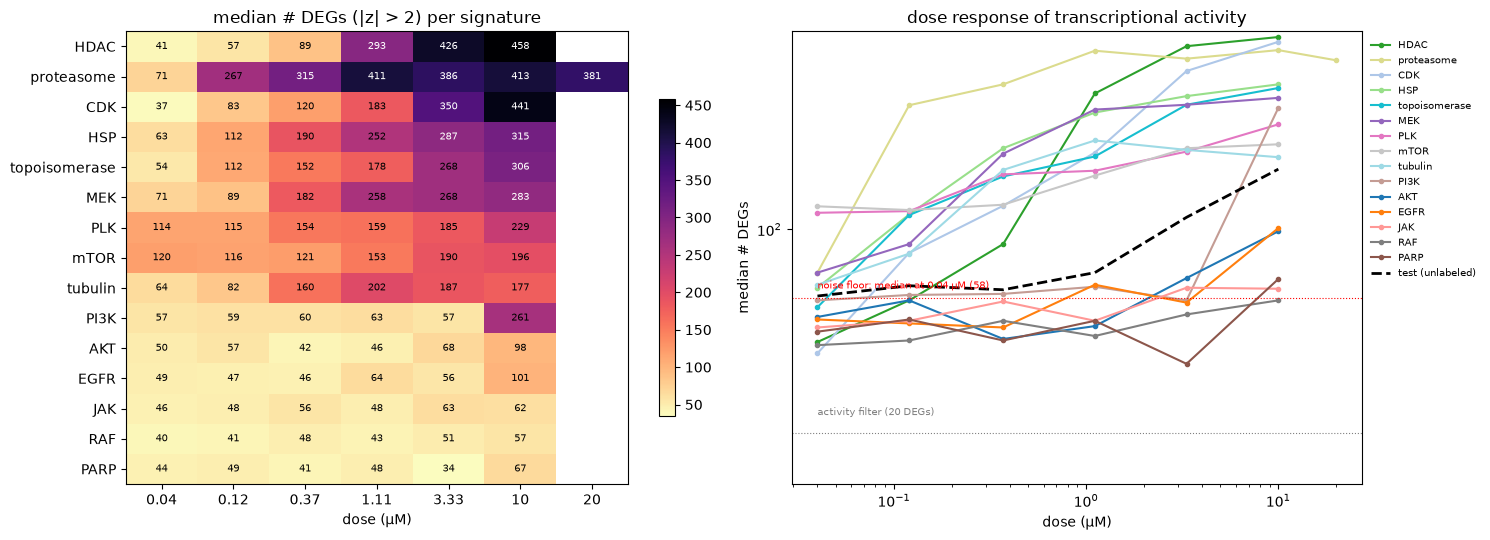

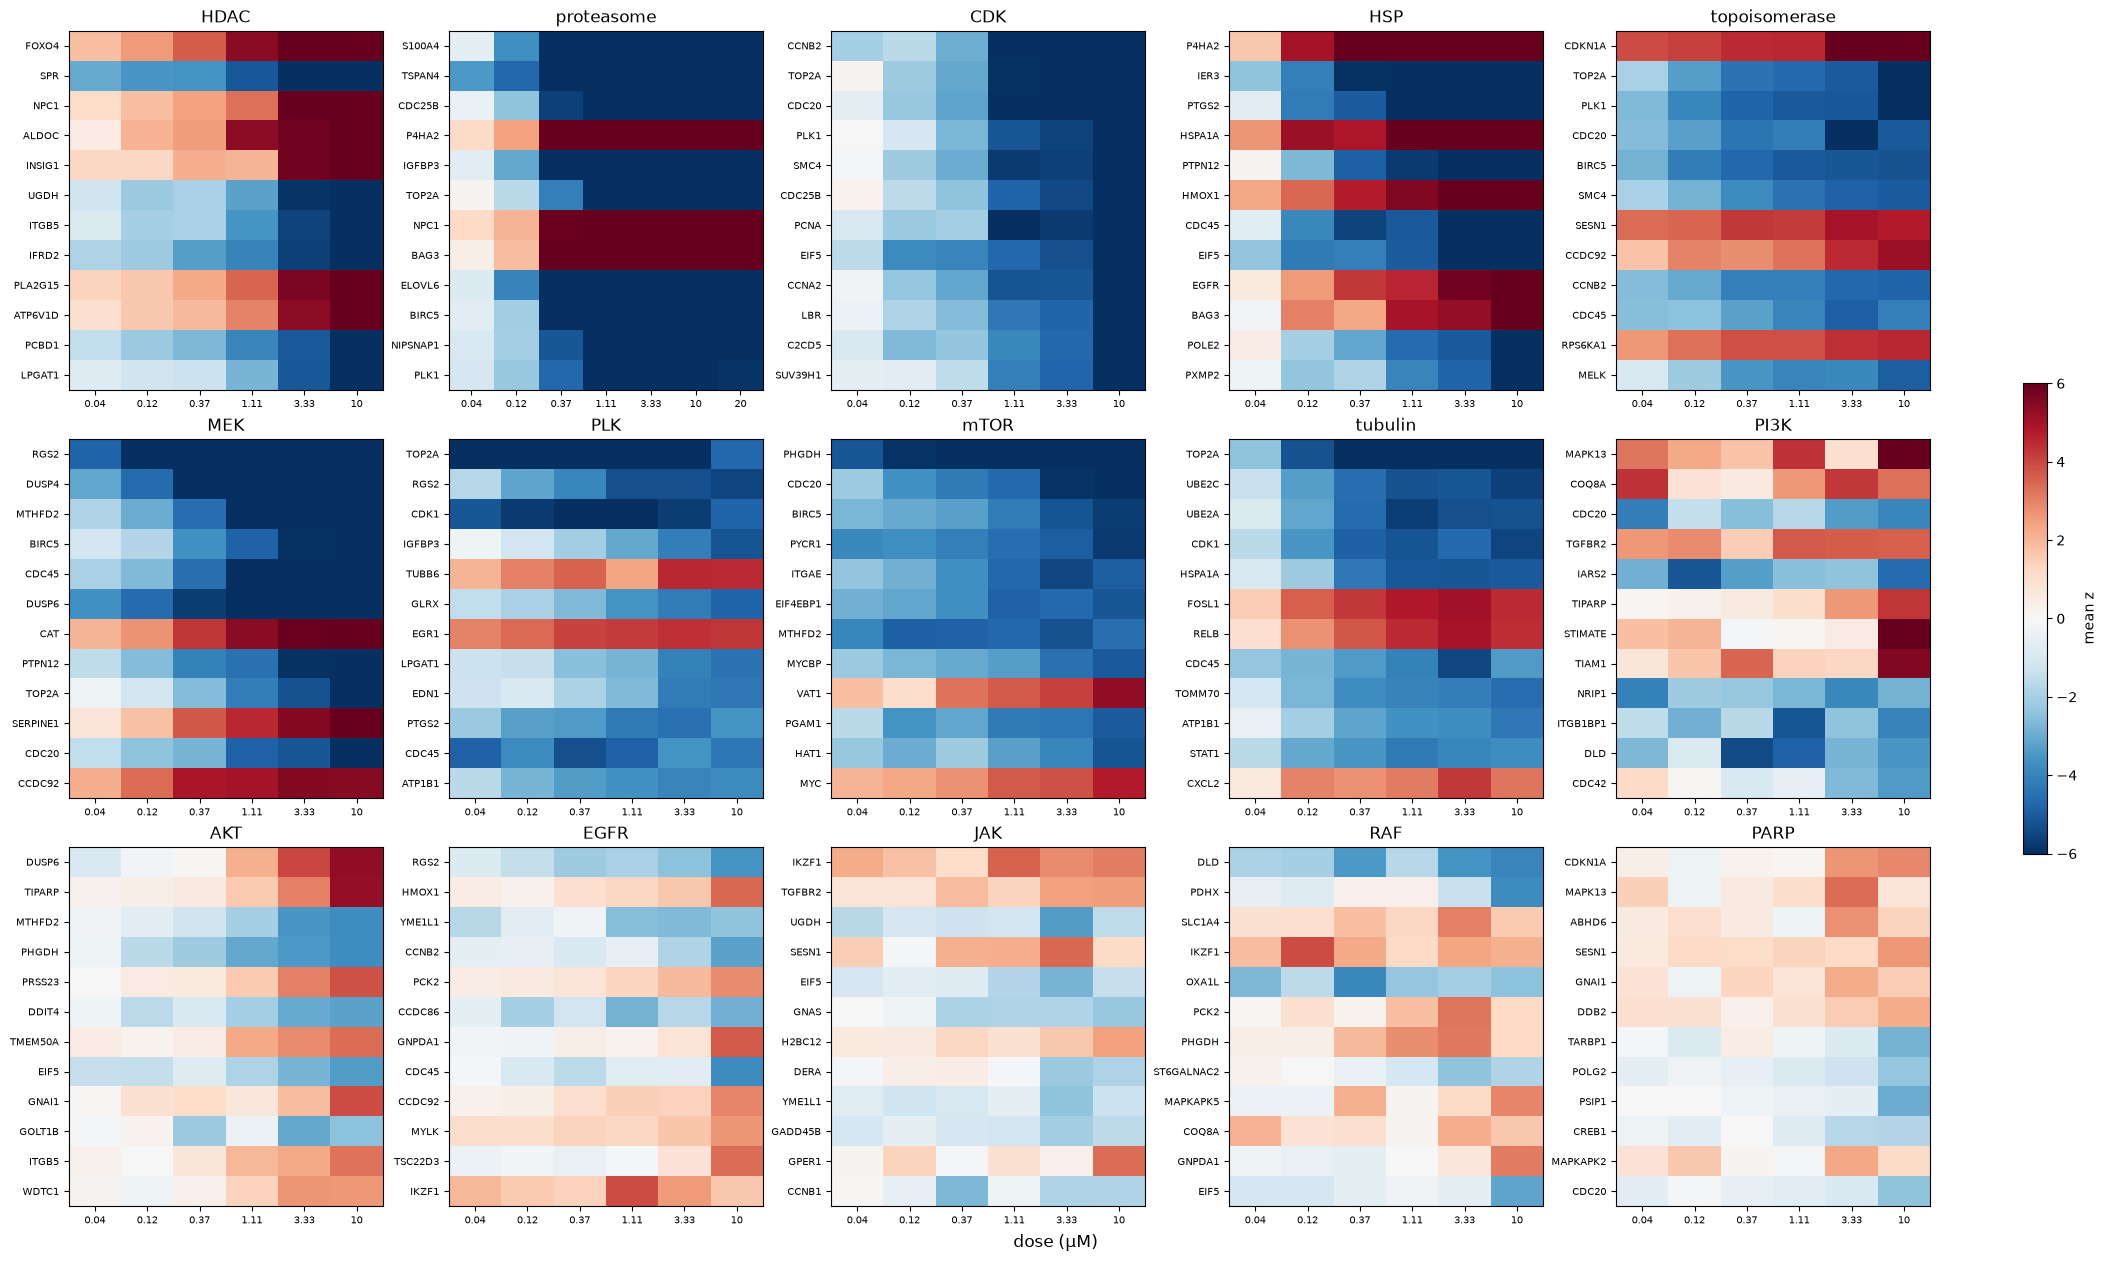

In [12]:
sym = pd.read_csv(ROOT / "pathway_resources" / "l1000_pathway_weights.csv", index_col=0)["symbol"].reindex(X.columns)
sym = sym.fillna(pd.Series(X.columns, index=X.columns))
deg, deg_te = (X.abs() > 2).sum(1), (Xte.abs() > 2).sum(1)
H = deg.groupby([y, meta.dose_um]).median().unstack()
H = H.loc[H[[3.33, 10.0]].mean(1).sort_values(ascending=False).index]; H.to_csv(OUT / "deg_per_class_dose.csv")
ccol = dict(zip(classes, plt.cm.tab20(np.linspace(0, 1, len(classes)))))

fig, axs = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw=dict(width_ratios=[1.1, 1]))
im = axs[0].imshow(H.values, cmap="magma_r", aspect="auto"); hmax = np.nanmax(H.values)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        if not np.isnan(H.iat[i, j]): axs[0].text(j, i, int(H.iat[i, j]), ha="center", va="center", fontsize=7, color="white" if H.iat[i, j] > .6 * hmax else "black")
axs[0].set(xticks=range(H.shape[1]), xticklabels=[f"{d:g}" for d in H.columns], yticks=range(len(H)), yticklabels=[short(c) for c in H.index],
           xlabel="dose (µM)", title="median # DEGs (|z| > 2) per signature")
fig.colorbar(im, ax=axs[0], shrink=.7)
for c in H.index: axs[1].plot(H.columns, H.loc[c], "-o", ms=3, color=ccol[c], label=short(c))
td = deg_te.groupby(mte.dose_um).median(); axs[1].plot(td.index, td.values, "k--", lw=2, label="test (unlabeled)")
axs[1].axhline(MIN_ACTIVE, color="grey", lw=.8, ls=":"); axs[1].text(0.04, MIN_ACTIVE * 1.15, f"activity filter ({MIN_ACTIVE} DEGs)", fontsize=7, color="grey")
nf = deg[meta.dose_um == 0.04].median(); axs[1].axhline(nf, color="red", lw=.8, ls=":"); axs[1].text(0.04, nf * 1.08, f"noise floor: median at 0.04 µM ({nf:.0f})", fontsize=7, color="red")
axs[1].set(xscale="log", yscale="symlog", xlabel="dose (µM)", ylabel="median # DEGs", title="dose response of transcriptional activity")
axs[1].legend(fontsize=7, frameon=False, bbox_to_anchor=(1, 1), loc="upper left")
fig.tight_layout(); fig.savefig(OUT / "fig_deg_per_class_dose.png", dpi=150)

Mz = X.groupby([y, meta.dose_um]).mean(); topg = {}
fig, axs = plt.subplots(3, 5, figsize=(21, 12.5), constrained_layout=True)
for ax, c in zip(axs.flat, H.index):
    m = Mz.loc[c]; mh = m.loc[m.index >= 3.33].mean(); top = mh.abs().nlargest(12).index; topg[c] = mh[mh.abs().nlargest(20).index]
    im = ax.imshow(m[top].T.values, cmap="RdBu_r", vmin=-6, vmax=6, aspect="auto")
    ax.set(title=short(c), xticks=range(len(m)), yticks=range(len(top))); ax.set_xticklabels([f"{d:g}" for d in m.index], fontsize=7); ax.set_yticklabels(sym[top].values, fontsize=7)
fig.colorbar(im, ax=axs.ravel().tolist(), shrink=.4, label="mean z"); fig.supxlabel("dose (µM)")
fig.savefig(OUT / "fig_top_genes_per_class_dose.png", dpi=130)
pd.concat({c: pd.DataFrame({"symbol": sym[v.index].values, "mean_z_hi_dose": v.round(2).values}) for c, v in topg.items()}, names=["class", "rank"]).to_csv(OUT / "top_genes_per_class.csv")
H.round(0)

## Plot 2: within-class variability of signatures
Signatures at ≥ 3.33 µM. Left: per-gene SD across all signatures of the class, with the noise floor (per-gene SD at the lowest dose, 0.04 µM, which is close to untreated). Right: variability **within** compounds (across doses ≥ 3.33 µM and replicates) vs **between** compounds of the same class, against the class signal (RMS of the class-mean profile). A class whose between-compound SD is far above its signal has no shared signature to learn.

,n_cpd,n_sig,sd_all,sd_within_compound,sd_between_compound,signal_rms,snr
cls,,,,,,,
HDAC inhibitor,9,18,1.613,0.825,1.404,2.076,1.478
proteasome inhibitor,4,12,1.237,0.771,0.952,2.532,2.661
CDK inhibitor,6,12,2.055,0.942,1.839,1.978,1.075
HSP inhibitor,4,8,0.937,0.615,0.743,1.893,2.548
topoisomerase inhibitor,11,22,1.672,0.900,1.403,1.497,1.067
MEK inhibitor,7,14,0.951,0.573,0.771,1.835,2.381
PLK inhibitor,4,8,1.145,0.651,0.985,1.297,1.317
mTOR inhibitor,4,8,0.996,0.573,0.837,1.437,1.716
tubulin polymerization inhibitor,8,15,1.088,0.557,0.940,1.161,1.235


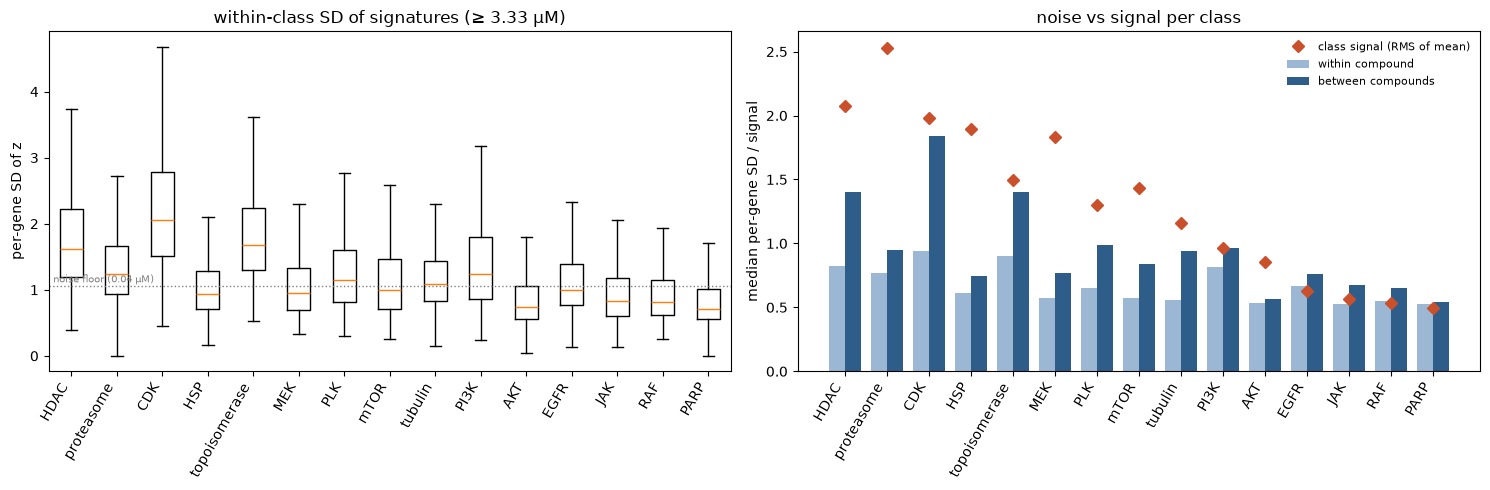

In [13]:
hi_tr = meta.dose_um >= 3.33
noise = X[meta.dose_um == 0.04].std()
rows, sds = [], {}
for c in H.index:
    Xi = X[hi_tr & (y == c)]; g = meta.compound[Xi.index]; cm_ = Xi.groupby(g).mean()
    sds[c] = Xi.std()
    sig = float(np.sqrt((cm_.mean() ** 2).mean()))
    rows.append(dict(cls=c, n_cpd=g.nunique(), n_sig=len(Xi), sd_all=sds[c].median(), sd_within_compound=Xi.groupby(g).std().mean().median(),
                     sd_between_compound=cm_.std().median(), signal_rms=sig, snr=sig / cm_.std().median()))
var = pd.DataFrame(rows).set_index("cls").round(3); var.to_csv(OUT / "class_variability.csv")

fig, axs = plt.subplots(1, 2, figsize=(15, 5))
axs[0].boxplot([sds[c].values for c in H.index], showfliers=False)
axs[0].axhline(noise.median(), color="grey", ls=":", lw=1); axs[0].text(.6, noise.median() * 1.05, "noise floor (0.04 µM)", fontsize=7, color="grey")
axs[0].set_xticks(range(1, len(H) + 1)); axs[0].set_xticklabels([short(c) for c in H.index], rotation=60, ha="right")
axs[0].set(ylabel="per-gene SD of z", title="within-class SD of signatures (≥ 3.33 µM)")
xx = np.arange(len(var)); w = .38
axs[1].bar(xx - w / 2, var.sd_within_compound, w, label="within compound", color="#9bb7d4")
axs[1].bar(xx + w / 2, var.sd_between_compound, w, label="between compounds", color="#2f5d8a")
axs[1].plot(xx, var.signal_rms, "D", color="#c9502a", label="class signal (RMS of mean)")
axs[1].set_xticks(xx); axs[1].set_xticklabels([short(c) for c in var.index], rotation=60, ha="right")
axs[1].set(ylabel="median per-gene SD / signal", title="noise vs signal per class"); axs[1].legend(fontsize=8, frameon=False)
fig.tight_layout(); fig.savefig(OUT / "fig_class_variability.png", dpi=150)
var

## Plot 3: clustering, where the unlabeled compounds fall, normalization and batch effect
Batch = plate (the `REP.A0xx` part of the sample id). Three versions of the data:
1. **raw z** as given;
2. **gene-normalized**: each gene robust-scaled (median / MAD over all signatures), rescaled to the median gene MAD so |z| > 2 keeps its meaning;
3. **plate-centred + gene-normalized**: the per-plate, per-gene median is subtracted first (label-free; uses train and test plates).

t-SNE of signatures at ≥ 3.33 µM. Top row: by class, test compounds as black ×, `X_unlabeled` (if present in the data folder) as grey dots. Bottom row: the same embedding by plate. Titles: cosine silhouette by class and by plate (training signatures, PCA-30 space) and the share of signatures whose nearest neighbour from **another** compound has the same class. Last: does the correction help the models? (official `cv_fold` CV, multiclass)

X_unlabeled.csv.gz not found in /home/aaleyasin/Projects/Omics-Hackathon2026 - test compounds are the unlabeled set here


,silhouette_class,silhouette_plate,nn_other_compound_same_class
version,,,
raw z,0.152,-0.252,0.621
gene-normalized,-0.721,-0.694,0.542
plate-centred + gene-normalized,-0.681,-0.727,0.531


version,raw z,gene-normalized,plate-centred + gene-normalized
model,,,
centroid,0.6563,0.4546,0.3436
knn,0.6382,0.6382,0.5224
logreg,0.6137,0.6321,0.5805
mlp,0.6663,0.5964,0.5631
rf,0.6649,0.6883,0.5659


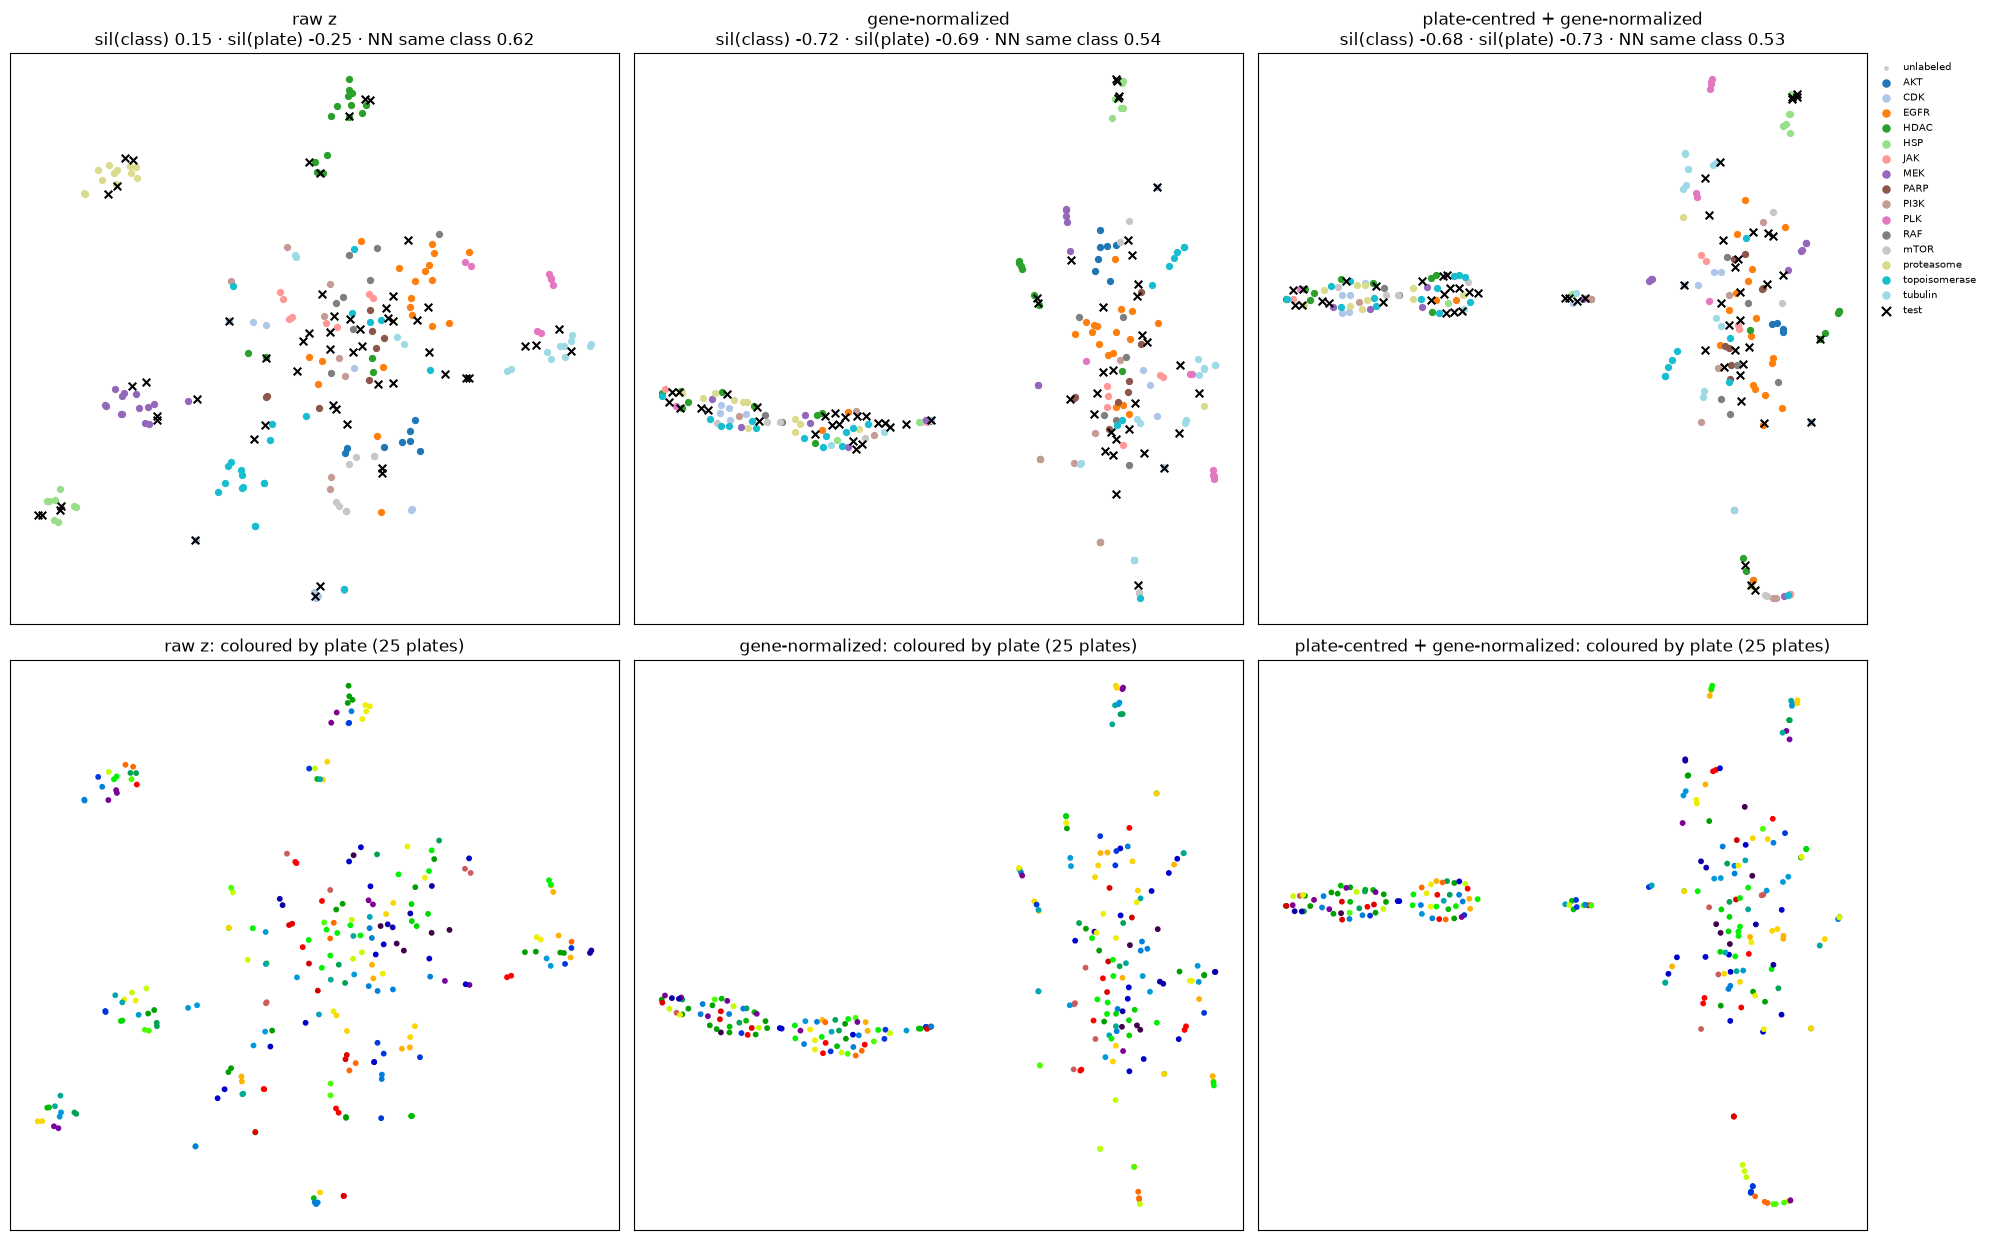

In [14]:
ul = ROOT / "X_unlabeled.csv.gz"
blocks, dose = {"train": X, "test": Xte}, pd.concat([meta.dose_um, mte.dose_um])
if ul.exists():
    U = pd.read_csv(ul, index_col=0); blocks["unlabeled"] = U[X.columns]; dose = pd.concat([dose, U.dose_um])
else: print("X_unlabeled.csv.gz not found in", ROOT.resolve(), "- test compounds are the unlabeled set here")
A = pd.concat(blocks.values()); srcs = pd.Series(np.repeat(list(blocks), [len(v) for v in blocks.values()]), index=A.index)
plate = pd.Series([i.split(":")[0] if ":" in i else "unknown" for i in A.index], index=A.index)

def gnorm(Z):
    med = Z.median(); mad = 1.4826 * (Z - med).abs().median() + 1e-6
    return (Z - med) / mad * mad.median()
VERS = {"raw z": A, "gene-normalized": gnorm(A), "plate-centred + gene-normalized": gnorm(A - A.groupby(plate).transform("median"))}

idx = A.index[(dose.loc[A.index] >= 3.33).values]; tr_idx = idx[(srcs[idx] == "train").values]
emb, qual = {}, []
for name, Z in VERS.items():
    Zp = pd.DataFrame(PCA(30, random_state=SEED).fit_transform(Z.loc[idx]), index=idx)
    emb[name] = pd.DataFrame(TSNE(2, perplexity=30, init="pca", random_state=SEED).fit_transform(Zp.values), index=idx)
    Zt = Zp.loc[tr_idx].values; Un = Zt / np.linalg.norm(Zt, axis=1, keepdims=True); Sm = Un @ Un.T
    same = meta.compound[tr_idx].to_numpy(object); Sm[same[:, None] == same[None]] = -np.inf
    qual.append(dict(version=name, silhouette_class=silhouette_score(Zt, y[tr_idx], metric="cosine"),
                     silhouette_plate=silhouette_score(Zt, plate[tr_idx], metric="cosine"),
                     nn_other_compound_same_class=(y[tr_idx].to_numpy(object)[Sm.argmax(1)] == y[tr_idx].to_numpy(object)).mean()))
qual = pd.DataFrame(qual).set_index("version").round(3)

pl = sorted(plate.unique()); pcol = dict(zip(pl, plt.cm.nipy_spectral(np.linspace(0.03, .97, len(pl)))))
fig, axs = plt.subplots(2, 3, figsize=(20, 12.5))
for j, (name, E) in enumerate(emb.items()):
    q = qual.loc[name]; ax = axs[0, j]
    u = idx[(srcs[idx] == "unlabeled").values]; ax.scatter(E.loc[u, 0], E.loc[u, 1], s=4, c="#cccccc", label="unlabeled")
    for c in classes:
        t = tr_idx[(y[tr_idx] == c).values]; ax.scatter(E.loc[t, 0], E.loc[t, 1], s=18, color=ccol[c], label=short(c))
    te = idx[(srcs[idx] == "test").values]; ax.scatter(E.loc[te, 0], E.loc[te, 1], s=30, marker="x", c="k", label="test")
    ax.set(title=f"{name}\nsil(class) {q.silhouette_class:.2f} · sil(plate) {q.silhouette_plate:.2f} · NN same class {q.nn_other_compound_same_class:.2f}", xticks=[], yticks=[])
    ax = axs[1, j]
    ax.scatter(E[0], E[1], s=10, c=[pcol[p] for p in plate[idx]]); ax.set(title=f"{name}: coloured by plate ({len(pl)} plates)", xticks=[], yticks=[])
axs[0, -1].legend(fontsize=7, frameon=False, bbox_to_anchor=(1, 1), loc="upper left", markerscale=1.2)
fig.tight_layout(); fig.savefig(OUT / "fig_embedding_batch.png", dpi=130)

vn = list(VERS)[1:]
p2 = Parallel(n_jobs=-1)(delayed(scores)(n, "multiclass", VERS[v].loc[X.index].iloc[a], y.iloc[a], VERS[v].loc[X.index].iloc[b]) for v in vn for n in MODELS for a, b in folds)
bc = [dict(version="raw z", model=n, macro_f1=f1o[n, "multiclass"]) for n in MODELS]
for i, (v, n) in enumerate([(v, n) for v in vn for n in MODELS]):
    bc.append(dict(version=v, model=n, macro_f1=metrics_of(pd.concat(p2[i * len(folds):(i + 1) * len(folds)]))["macro_f1"]))
bc = pd.DataFrame(bc).pivot(index="model", columns="version", values="macro_f1")[list(VERS)]
qual.to_csv(OUT / "embedding_quality.csv"); bc.to_csv(OUT / "batch_correction_cv.csv")
display(qual); bc

## Plot 4: how close are the signatures, within and across classes?
Compound profile = mean signature at ≥ 3.33 µM. Left: Pearson correlation between all training compounds, grouped by class. Middle: mean correlation between classes (diagonal = between *different* compounds of the same class). Right: each test compound's correlation with each class centroid.

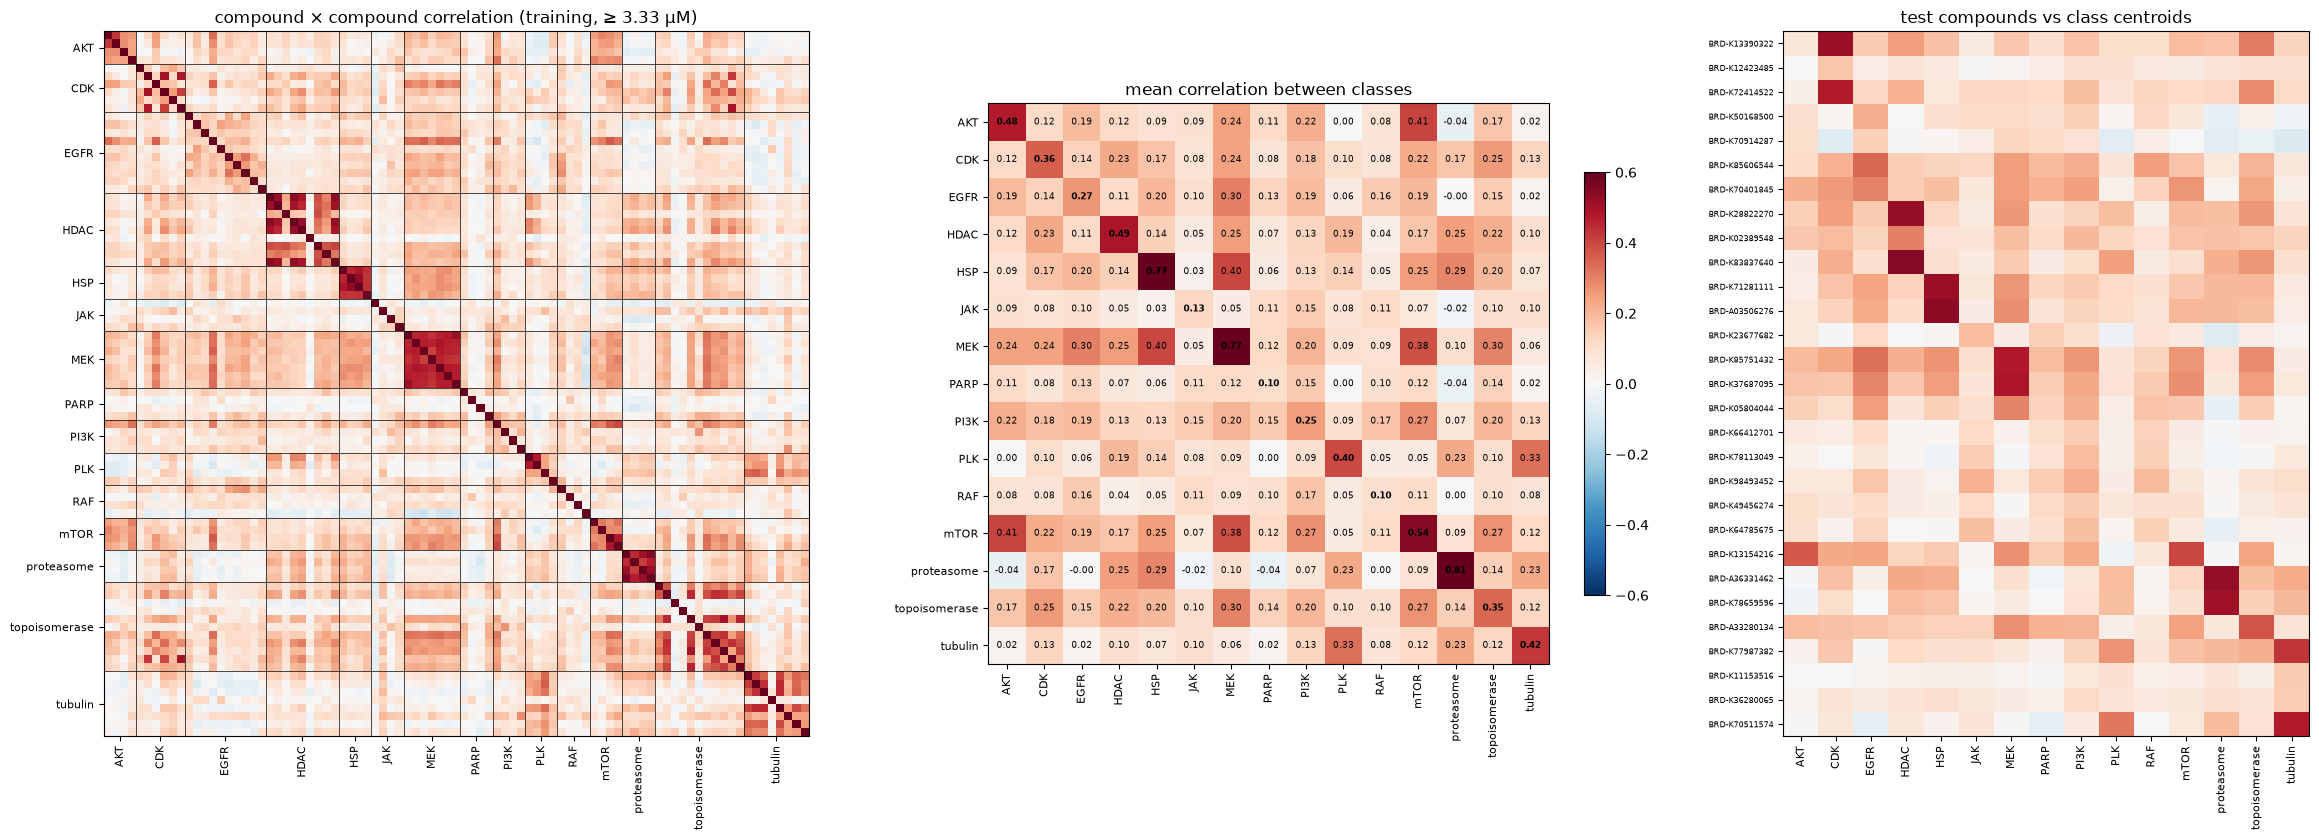

In [15]:
prof = pd.concat([X, Xte])[allm.dose_um >= 3.33].groupby(allm.compound[allm.dose_um >= 3.33]).mean()
Ctr = prof.loc[cpd.sort_values().index]; labc = cpd.loc[Ctr.index].to_numpy(object)
R = pd.DataFrame(np.corrcoef(Ctr.values), index=Ctr.index, columns=Ctr.index); R.round(3).to_csv(OUT / "compound_similarity.csv")
def block(a, b):
    M = R.values[np.ix_(labc == a, labc == b)]
    return M[~np.eye(len(M), dtype=bool)].mean() if a == b else M.mean()
CC = pd.DataFrame([[block(a, b) for b in classes] for a in classes], index=classes, columns=classes); CC.round(3).to_csv(OUT / "class_similarity.csv")
z = lambda M: (M - M.mean(1, keepdims=True)) / M.std(1, keepdims=True)
cen = Ctr.groupby(labc).mean().loc[classes]; Cte = prof.loc[mte.compound.unique()]
TC = pd.DataFrame(z(Cte.values) @ z(cen.values).T / Cte.shape[1], index=Cte.index, columns=classes)
TC = TC.loc[TC.idxmax(1).map(classes.index).sort_values().index]; TC.round(3).to_csv(OUT / "test_vs_class_centroid_corr.csv")

fig, axs = plt.subplots(1, 3, figsize=(24, 8.5), gridspec_kw=dict(width_ratios=[1.25, 1, .75]))
axs[0].imshow(R.values, cmap="RdBu_r", vmin=-1, vmax=1)
edges = np.flatnonzero(labc[1:] != labc[:-1]) + .5; mids = [np.flatnonzero(labc == c).mean() for c in classes]
for e in edges: axs[0].axhline(e, color="k", lw=.5); axs[0].axvline(e, color="k", lw=.5)
axs[0].set(xticks=mids, yticks=mids, title="compound × compound correlation (training, ≥ 3.33 µM)")
axs[0].set_xticklabels(map(short, classes), rotation=90, fontsize=8); axs[0].set_yticklabels(map(short, classes), fontsize=8)
im = axs[1].imshow(CC.values, cmap="RdBu_r", vmin=-.6, vmax=.6)
for i in range(15):
    for k in range(15): axs[1].text(k, i, f"{CC.iat[i, k]:.2f}", ha="center", va="center", fontsize=6.5, fontweight="bold" if i == k else None)
axs[1].set(xticks=range(15), yticks=range(15), title="mean correlation between classes")
axs[1].set_xticklabels(map(short, classes), rotation=90, fontsize=8); axs[1].set_yticklabels(map(short, classes), fontsize=8)
fig.colorbar(im, ax=axs[1], shrink=.6)
axs[2].imshow(TC.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
axs[2].set(xticks=range(15), yticks=range(len(TC)), title="test compounds vs class centroids")
axs[2].set_xticklabels(map(short, classes), rotation=90, fontsize=8); axs[2].set_yticklabels(TC.index, fontsize=6)
fig.tight_layout(); fig.savefig(OUT / "fig_similarity.png", dpi=130)

## Why are some targets not learned?
One row per class: recall (official CV, mean over the 10 base models, and the best model), which class its compounds go to instead, signal strength (DEGs at ≥ 3.33 µM, share of signatures passing the activity filter), coherence (mean correlation between its compounds, the most similar other class, nearest-neighbour purity), the signal-to-noise ratio from plot 2, and the median pathway readout of its own prior (NaN = no prior, e.g. HDAC). `reason` is a rule of thumb applied in this order to classes with mean recall < 0.5: median DEGs at ≥ 3.33 µM below 2× the noise floor (median DEGs at 0.04 µM, near-untreated) → **silent**; within-class r < 0.2 → **heterogeneous**; another class at least as close → **overlaps**; otherwise **few compounds**.

,n_compounds,mean_recall,best_recall,best_model,confused_with,share_to_it,median_DEGs_hi,frac_sigs_active,within_class_r,nearest_class,nearest_class_r,nn_same_class,snr,own_pathway_readout,reason
JAK inhibitor,4,0.00,0.00,centroid|per_class,EGFR,0.45,62.75,1.00,0.13,PI3K,0.15,0.00,0.83,1.17,silent: DEGs at ≥3.33 µM < 2× noise floor (58)
PARP inhibitor,4,0.15,0.25,centroid|per_class,EGFR,0.30,51.00,0.83,0.10,PI3K,0.15,0.00,0.91,0.61,silent: DEGs at ≥3.33 µM < 2× noise floor (58)
RAF inhibitor,4,0.15,0.50,rf|multiclass,PI3K,0.28,54.00,1.00,0.10,PI3K,0.17,0.25,0.81,0.42,silent: DEGs at ≥3.33 µM < 2× noise floor (58)
PI3K inhibitor,4,0.32,0.75,centroid|multiclass,mTOR,0.30,159.25,1.00,0.25,mTOR,0.27,0.00,1.00,-0.14,overlaps with mTOR
AKT inhibitor,4,0.55,1.00,rf|multiclass,PI3K,0.18,83.25,1.00,0.48,mTOR,0.41,0.75,1.50,0.56,learned
CDK inhibitor,6,0.67,0.83,knn|per_class,HDAC,0.10,395.50,0.97,0.36,topoisomerase,0.25,0.67,1.08,0.91,learned
EGFR inhibitor,10,0.68,0.90,rf|per_class,MEK,0.14,78.50,0.97,0.27,MEK,0.30,0.70,0.82,1.35,learned
topoisomerase inhibitor,11,0.75,0.82,logreg|per_class,EGFR,0.11,287.00,0.94,0.35,MEK,0.30,0.64,1.07,1.74,learned
tubulin polymerization inhibitor,8,0.80,0.88,knn|per_class,EGFR,0.06,182.25,1.00,0.42,PLK,0.33,0.75,1.24,0.43,learned
PLK inhibitor,4,0.80,1.00,knn|per_class,tubulin,0.20,207.25,1.00,0.40,tubulin,0.33,0.50,1.32,1.03,learned


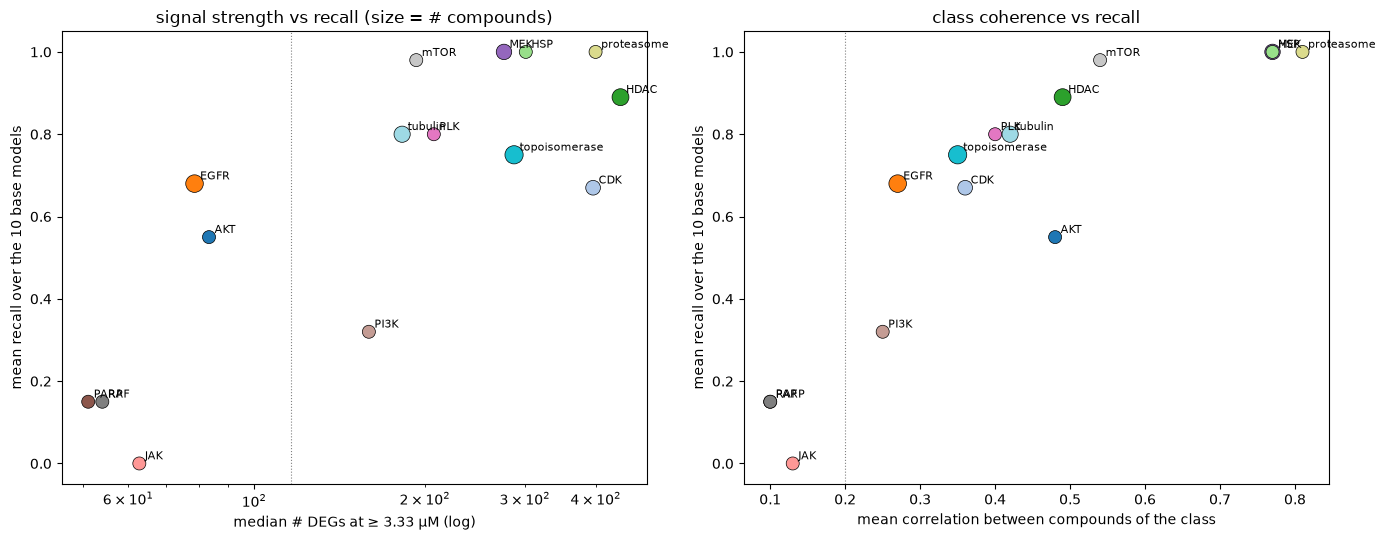

In [16]:
deg_floor = deg[meta.dose_um == 0.04].median()   # DEGs of a near-untreated signature
base = [(n, m) for n in MODELS for m in MODES]
csum = sum(CM[j] for j in base); off = csum.where(~np.eye(15, dtype=bool), 0)
Rm = R.values.copy(); np.fill_diagonal(Rm, -np.inf)
nnp = pd.Series(labc[Rm.argmax(1)] == labc, index=Ctr.index).groupby(labc).mean()
CCo = CC.where(~np.eye(15, dtype=bool))
rb = rec[[f"{n}|{m}" for n, m in base]]
diag = pd.DataFrame({
    "n_compounds": cpd.value_counts(), "mean_recall": rb.mean(1), "best_recall": rb.max(1), "best_model": rb.idxmax(1),
    "confused_with": off.idxmax(1).map(short).where(off.max(1) > 0, "-"), "share_to_it": off.max(1) / csum.sum(1),
    "median_DEGs_hi": H[[3.33, 10.0]].mean(1), "frac_sigs_active": (deg >= MIN_ACTIVE).groupby(y).mean(),
    "within_class_r": pd.Series(np.diag(CC), index=classes), "nearest_class": CCo.idxmax(1).map(short), "nearest_class_r": CCo.max(1),
    "nn_same_class": nnp, "snr": var.snr, "own_pathway_readout": support(cpd.index, cpd.values).groupby(cpd).median()}).loc[classes]

def reason(r):
    if r.mean_recall >= .5: return "learned"
    if r.median_DEGs_hi < 2 * deg_floor: return f"silent: DEGs at ≥3.33 µM < 2× noise floor ({deg_floor:.0f})"
    if r.within_class_r < .2: return "heterogeneous: compounds share no signature"
    if r.nearest_class_r >= r.within_class_r - .05: return f"overlaps with {r.nearest_class}"
    return "few compounds / weak separation"
diag["reason"] = diag.apply(reason, axis=1)
diag = diag.sort_values("mean_recall").round(2); diag.to_csv(OUT / "class_diagnosis.csv")

fig, axs = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, xcol, xl in [(axs[0], "median_DEGs_hi", "median # DEGs at ≥ 3.33 µM (log)"), (axs[1], "within_class_r", "mean correlation between compounds of the class")]:
    ax.scatter(diag[xcol], diag.mean_recall, s=40 + 12 * diag.n_compounds, c=[ccol[c] for c in diag.index], edgecolor="k", lw=.5)
    for c, r in diag.iterrows(): ax.annotate(short(c), (r[xcol], r.mean_recall), fontsize=8, xytext=(4, 3), textcoords="offset points")
    ax.set(xlabel=xl, ylabel="mean recall over the 10 base models", ylim=(-.05, 1.05))
axs[0].set_xscale("log"); axs[0].axvline(2 * deg_floor, color="grey", ls=":", lw=.8); axs[1].axvline(.2, color="grey", ls=":", lw=.8)
axs[0].set_title("signal strength vs recall (size = # compounds)"); axs[1].set_title("class coherence vs recall")
fig.tight_layout(); fig.savefig(OUT / "fig_class_diagnosis.png", dpi=150)
diag